**Задача 7. Векторизация вычислений**
- Использовать numpy.array вместо list (например, для хранения информации о всех фотонах в событии).
- Модифицировать методы для генерации, пропагации фотонов и вычисления числа фотоэлектронов так, чтобы они работали с массивами фотонов (numpy.array). Оценить выигрыш во времени от использования numpy по сравнению с итерацией по отдельным фотонам.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from numpy import pi, sin, cos, arccos, sqrt, random, column_stack

In [2]:
class Detector:
    def __init__(self, R=2.0, N=40, r_cm=10.0, a=0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r_cm) / 100.0
        self.a = float(a)
        self.centers = np.zeros((self.N, 3))
        self.distribute_on_detector()

    def distribute_on_detector(self):
        golden_ratio = (1 + 5 ** 0.5) / 2
        for i in range(self.N):
            theta = 2 * pi * i / golden_ratio
            phi = arccos(1 - 2 * (i + 0.5) / self.N)
            x, y, z = self.R * cos(theta) * sin(phi), self.R * sin(theta) * sin(phi), self.R * cos(phi)
            self.centers[i] = [x, y, z]

    def is_point_on(self, point):
        point = np.array(point)
        distances = np.linalg.norm(self.centers - point, axis=1)
        return bool(np.any(distances <= self.r))


class Source:
    def __init__(self, Y=10000):
        self.Y = float(Y)

    def generate_photons(self, E):
        expected_N = self.Y * E
        N = random.poisson(expected_N)
        cos_theta = random.uniform(-1.0, 1.0, N)
        phi = random.uniform(0.0, 2 * pi, N)
        sin_theta = sqrt(1.0 - cos_theta ** 2)
        x, y, z = sin_theta * cos(phi), sin_theta * sin(phi), cos_theta
        return column_stack((x, y, z))


def track_photon_to_boundary(start_pos, direction, detector):
    x0, y0, z0 = start_pos
    nx, ny, nz = direction
    a_coef = 1.0
    b_coef = 2.0 * (x0 * nx + y0 * ny + z0 * nz)
    c_coef = (x0 ** 2 + y0 ** 2 + z0 ** 2) - detector.R ** 2
    discriminant = b_coef ** 2 - 4.0 * a_coef * c_coef
    sqrt_disc = np.sqrt(discriminant)
    t1 = (-b_coef + sqrt_disc) / (2.0 * a_coef)
    t2 = (-b_coef - sqrt_disc) / (2.0 * a_coef)
    valid_t = [t for t in (t1, t2) if t > 0]
    t_hit = min(valid_t)
    hit_point = (x0 + t_hit * nx, y0 + t_hit * ny, z0 + t_hit * nz)
    return detector.is_point_on(hit_point)


def generate_photoelectrons(mean_a):
    return np.random.poisson(mean_a)


def simulate_events(E, num_events, start_pos, detector, source):
    charges = np.zeros(num_events)
    for i in range(num_events):
        directions = source.generate_photons(E)
        q_event = 0
        for direction in directions:
            if track_photon_to_boundary(start_pos, direction, detector):
                q_event += random.poisson(detector.a)
        charges[i] = q_event
    return charges

In [3]:
def is_point_on_batch(detector, points):
    points = np.asarray(points, dtype=float)
    diffs = points[:, np.newaxis, :] - detector.centers[np.newaxis, :, :]
    distances = np.linalg.norm(diffs, axis=2)
    point_on_batch = np.any(distances <= detector.r, axis=1)
    return point_on_batch


def track_photons_to_boundary_vectorized(start_pos, directions, detector):
    start_pos = np.asarray(start_pos, dtype=float)
    x0, y0, z0 = start_pos
    nx, ny, nz = directions[:, 0], directions[:, 1], directions[:, 2]

    a_coef = 1.0
    b_coef = 2.0 * (x0 * nx + y0 * ny + z0 * nz)
    c_coef = (x0 ** 2 + y0 ** 2 + z0 ** 2) - detector.R ** 2

    discriminant = b_coef ** 2 - 4.0 * a_coef * c_coef
    sqrt_disc = np.sqrt(discriminant)
    t1 = (-b_coef + sqrt_disc) / (2.0 * a_coef)
    t2 = (-b_coef - sqrt_disc) / (2.0 * a_coef)
    t_hit = np.maximum(t1, t2)

    hit_points = start_pos[np.newaxis, :] + t_hit[:, np.newaxis] * directions
    hits_pmt = is_point_on_batch(detector, hit_points)

    return hits_pmt, t_hit


def generate_photoelectrons_batch(mean_a, n):
    return np.random.poisson(mean_a, size=n)


def simulate_event_vectorized(E, start_pos, detector, source):
    directions = source.generate_photons(E)
    hits_pmt, _ = track_photons_to_boundary_vectorized(start_pos, directions, detector)
    n_hits = int(np.sum(hits_pmt))
    pe_per_hit = generate_photoelectrons_batch(detector.a, n_hits)
    event_vectorised = float(pe_per_hit.sum())
    return event_vectorised


def simulate_events_vectorized(E, num_events, start_pos, detector, source):
    charges = np.zeros(num_events)
    for i in range(num_events):
        charges[i] = simulate_event_vectorized(E, start_pos, detector, source)
    return charges

In [4]:
detector = Detector(R=2.0, N=40, r_cm=10.0, a=0.5)
source = Source(Y=10000)
start_pos = [0.0, 0.0, 0.0]

np.random.seed(2024)
charges_loop = simulate_events(1.0, 300, start_pos, detector, source)
np.random.seed(2024)
charges_vec = simulate_events_vectorized(1.0, 300, start_pos, detector, source)

print(f"цикл:         mean={charges_loop.mean():.2f}  std={charges_loop.std():.2f}")
print(f"векторизация: mean={charges_vec.mean():.2f}   std={charges_vec.std():.2f}")

assert np.array_equal(charges_loop, charges_vec), "результаты должны совпадать побитово при одинаковом seed!"
print("PASS: при одинаковом seed обе версии дают идентичный результат, фотон за фотоном.")

цикл:         mean=125.00  std=13.73
векторизация: mean=125.00   std=13.73
PASS: при одинаковом seed обе версии дают идентичный результат, фотон за фотоном.


In [5]:
energies_bench = [0.1, 0.5, 1.0, 3.0, 10.0]
n_events_fixed = 10

loop_times_E, vec_times_E, mean_photons_E = [], [], []

for E in energies_bench:
    np.random.seed(5)
    t0 = time.perf_counter()
    simulate_events(E, n_events_fixed, start_pos, detector, source)
    loop_times_E.append((time.perf_counter() - t0) / n_events_fixed)

    np.random.seed(5)
    t0 = time.perf_counter()
    simulate_events_vectorized(E, n_events_fixed, start_pos, detector, source)
    vec_times_E.append((time.perf_counter() - t0) / n_events_fixed)

    mean_photons_E.append(source.Y * E)
    print(f"E={E:5.1f} МэВ (~{source.Y*E:7.0f} фотонов/событие)  "
          f"цикл: {loop_times_E[-1]*1000:7.2f} мс/событие   "
          f"вектор.: {vec_times_E[-1]*1000:7.3f} мс/событие   "
          f"ускорение: {loop_times_E[-1]/vec_times_E[-1]:.1f}x")

E=  0.1 МэВ (~   1000 фотонов/событие)  цикл:    9.75 мс/событие   вектор.:   1.460 мс/событие   ускорение: 6.7x
E=  0.5 МэВ (~   5000 фотонов/событие)  цикл:   44.58 мс/событие   вектор.:   5.834 мс/событие   ускорение: 7.6x
E=  1.0 МэВ (~  10000 фотонов/событие)  цикл:   85.85 мс/событие   вектор.:  11.121 мс/событие   ускорение: 7.7x
E=  3.0 МэВ (~  30000 фотонов/событие)  цикл:  253.41 мс/событие   вектор.:  35.737 мс/событие   ускорение: 7.1x
E= 10.0 МэВ (~ 100000 фотонов/событие)  цикл:  807.08 мс/событие   вектор.: 110.884 мс/событие   ускорение: 7.3x


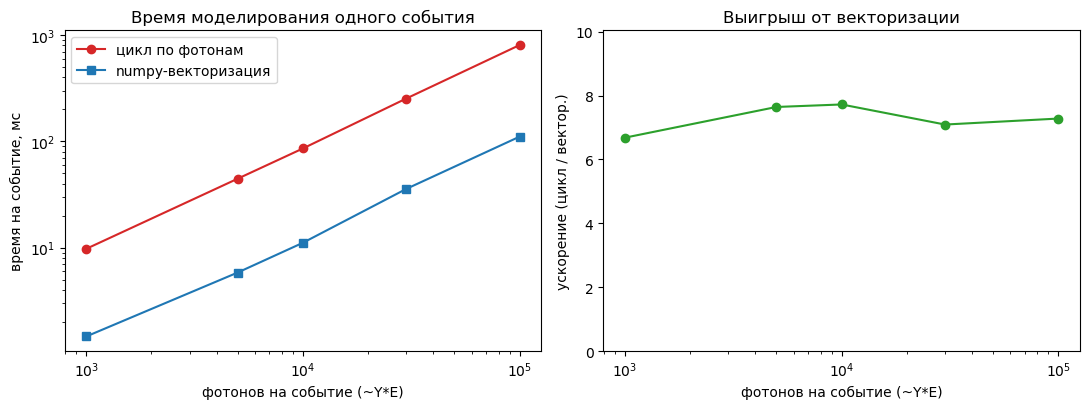

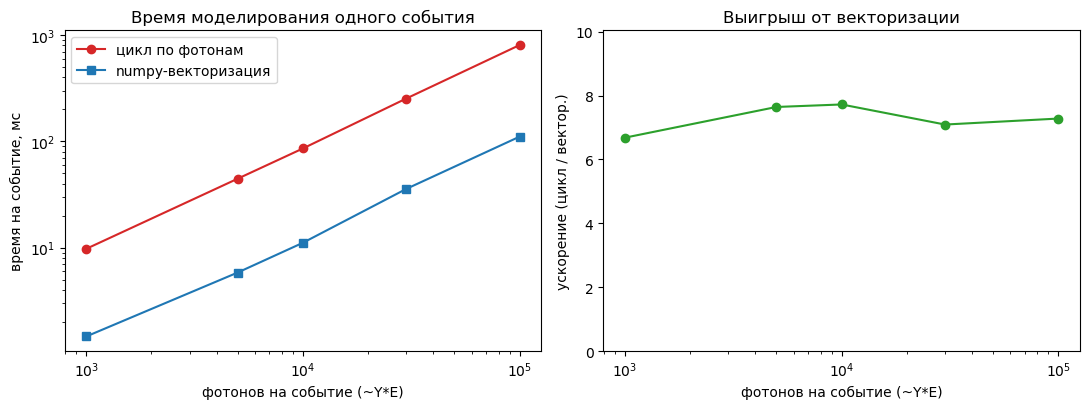

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(mean_photons_E, [t*1000 for t in loop_times_E], 'o-', color='tab:red', label='цикл по фотонам')
axes[0].plot(mean_photons_E, [t*1000 for t in vec_times_E], 's-', color='tab:blue', label='numpy-векторизация')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('фотонов на событие (~Y*E)')
axes[0].set_ylabel('время на событие, мс')
axes[0].set_title('Время моделирования одного события')
axes[0].legend()

speedups = [l/v for l, v in zip(loop_times_E, vec_times_E)]
axes[1].plot(mean_photons_E, speedups, 'o-', color='tab:green')
axes[1].set_xscale('log')
axes[1].set_xlabel('фотонов на событие (~Y*E)')
axes[1].set_ylabel('ускорение (цикл / вектор.)')
axes[1].set_title('Выигрыш от векторизации')
axes[1].set_ylim(0, max(speedups)*1.3)

fig.tight_layout()
fig